In [1]:
import pandas as pd
a=pd.read_csv("Downloads/daata science task dataset/task 4 dataset/netflix_titles.csv")
a

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [2]:
!pip install mplcursors

In [5]:
a.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [6]:
a['type'].value_counts()
     


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [7]:
!pip install mplcursors
     


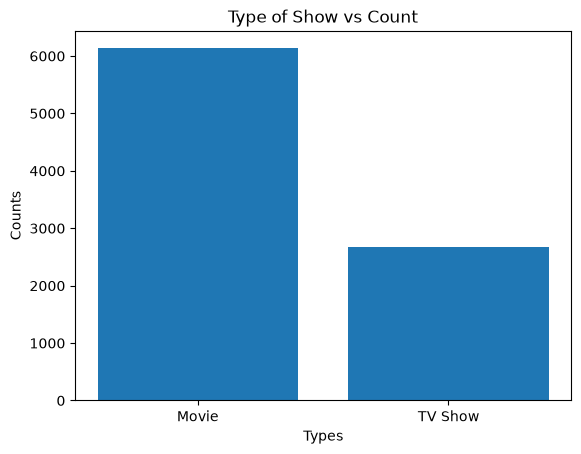

In [12]:
--1:

import matplotlib.pyplot as plt
import mplcursors

types = a['type'].value_counts()

bars = plt.bar(types.index, types.values)

plt.xlabel('Types')
plt.ylabel('Counts')
plt.title('Type of Show vs Count')

cursor = mplcursors.cursor(bars, hover=True)

@cursor.connect("add")
def on_hover(sel):
    sel.annotation.set_text(
        f"{types.index[sel.index]}\nCount: {types.values[sel.index]}")

plt.show()

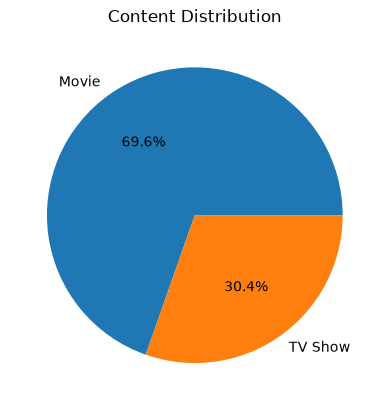

In [13]:
--2:
content = a['type'].value_counts()

pie = plt.pie(content.values, labels=content.index, autopct='%1.1f%%')
plt.title('Content Distribution')
plt.show()

In [14]:
--:
print(a['duration'])
movies = a[a['type'] == 'Movie'].copy()
movies['duration_num'] = movies['duration'].str.extract(r'(\d+)').astype(float)
movies = movies.dropna(subset=['duration_num'])

0          90 min
1       2 Seasons
2        1 Season
3        1 Season
4       2 Seasons
          ...    
8802      158 min
8803    2 Seasons
8804       88 min
8805       88 min
8806      111 min
Name: duration, Length: 8807, dtype: str


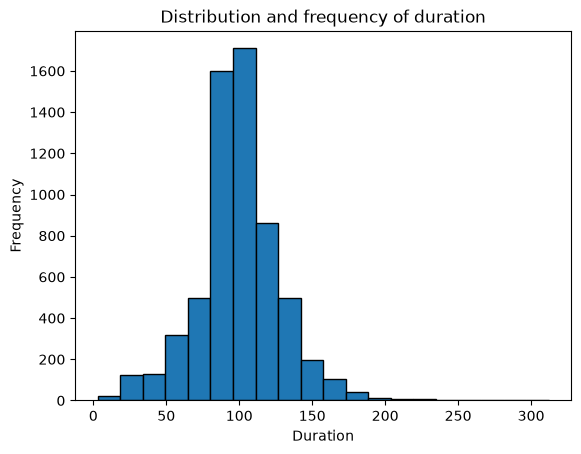

In [15]:
--3:
duration = movies['duration_num']
plt.hist(duration, bins=20, edgecolor='black')
plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.title('Distribution and frequency of duration')
plt.show()

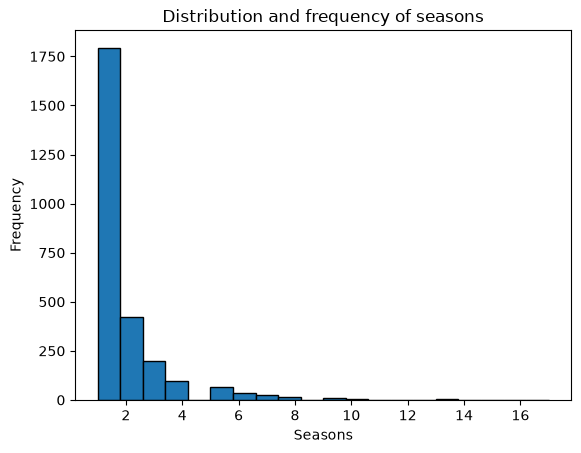

In [16]:

tv = a[a['type'] == 'TV Show'].copy()
tv['seasons'] = tv['duration'].str.extract(r'(\d+)').astype(float)
tv = tv.dropna(subset=['seasons'])

plt.hist(tv['seasons'], bins=20, edgecolor='black')
plt.xlabel('Seasons')
plt.ylabel('Frequency')
plt.title('Distribution and frequency of seasons')
plt.show()
     

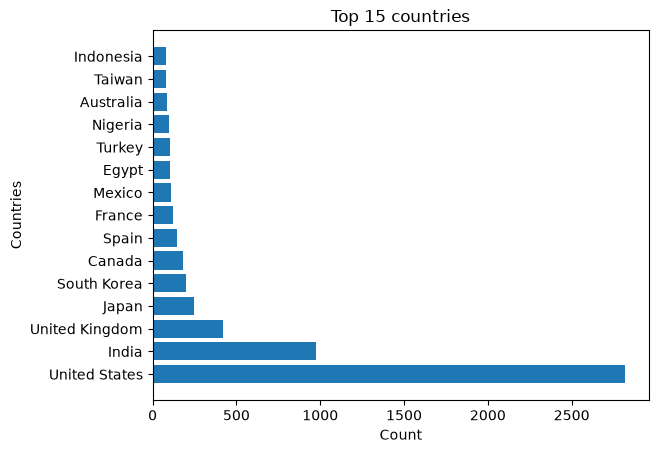

In [23]:
--4.
countries = a['country'].value_counts().head(15)

plt.barh(countries.index, countries.values)
plt.xlabel('Count')
plt.ylabel('Countries')
plt.title('Top 15 countries')
plt.show()

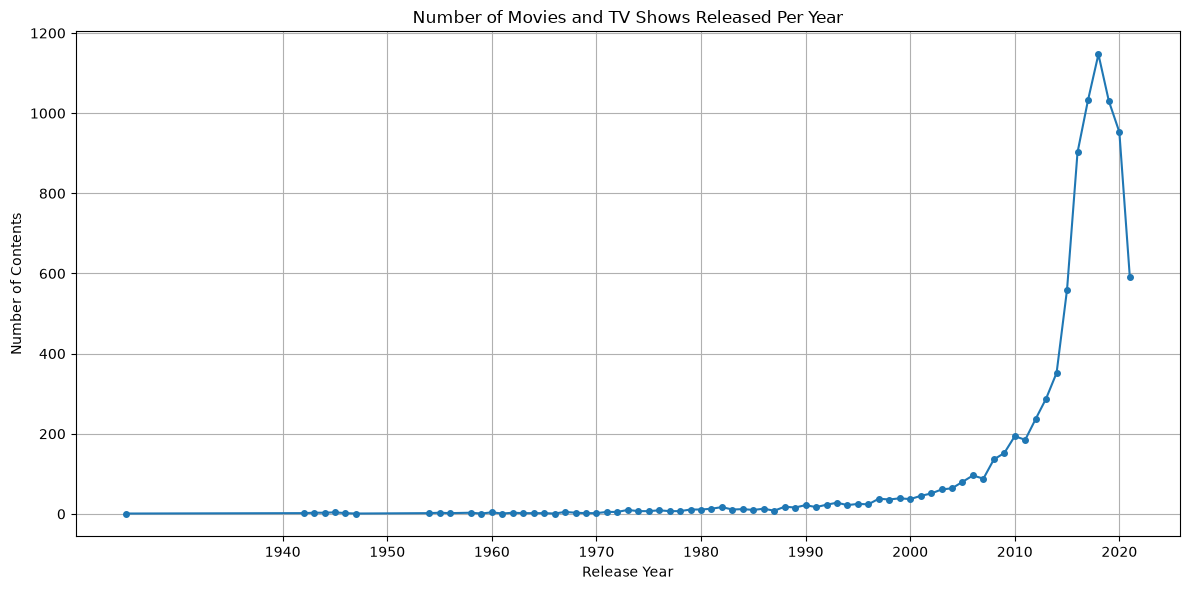

In [18]:
--5:
year = ['release_year'].value_counts().sort_index()
plt.figure(figsize=(12, 6))
plt.plot(year.index, year.values, marker='o', markersize=4)
plt.xlabel('Release Year')
plt.ylabel('Number of Contents')
plt.title('Number of Movies and TV Shows Released Per Year')
plt.grid(True)
plt.xticks(range(1940, 2026, 10))
plt.tight_layout()

plt.show()

Text(0, 0.5, 'Count')

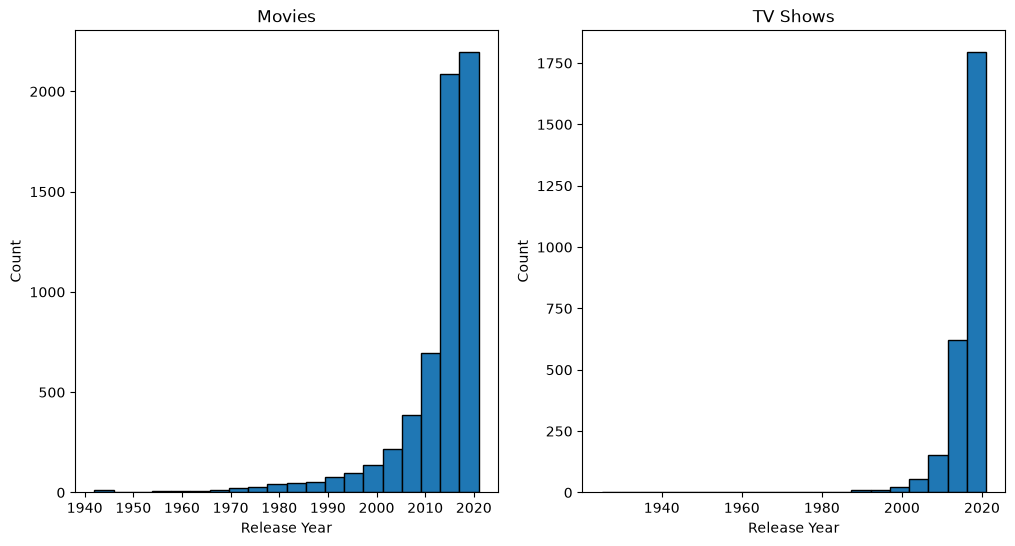

In [19]:
--6:
movies = a[a['type'] == 'Movie']
tv = a[a['type'] == 'TV Show']

plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.hist(movies['release_year'],bins=20, edgecolor='black')
plt.title('Movies')
plt.xlabel('Release Year')
plt.ylabel('Count')

plt.subplot(1,2,2)
plt.hist(tv['release_year'],bins=20, edgecolor='black')
plt.title('TV Shows')
plt.xlabel('Release Year')
plt.ylabel('Count')

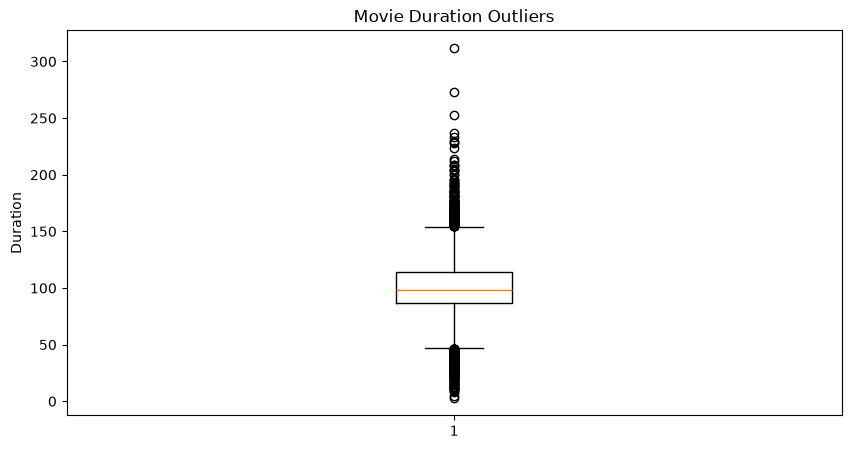

In [20]:
--8:
movies = a[a['type'] == 'Movie']
duration = movies['duration'].str.extract(r'(\d+)').astype(float)
duration = duration.dropna()
plt.figure(figsize=(10, 5))
plt.boxplot(duration[0])
plt.title('Movie Duration Outliers')
plt.ylabel('Duration')
plt.show()

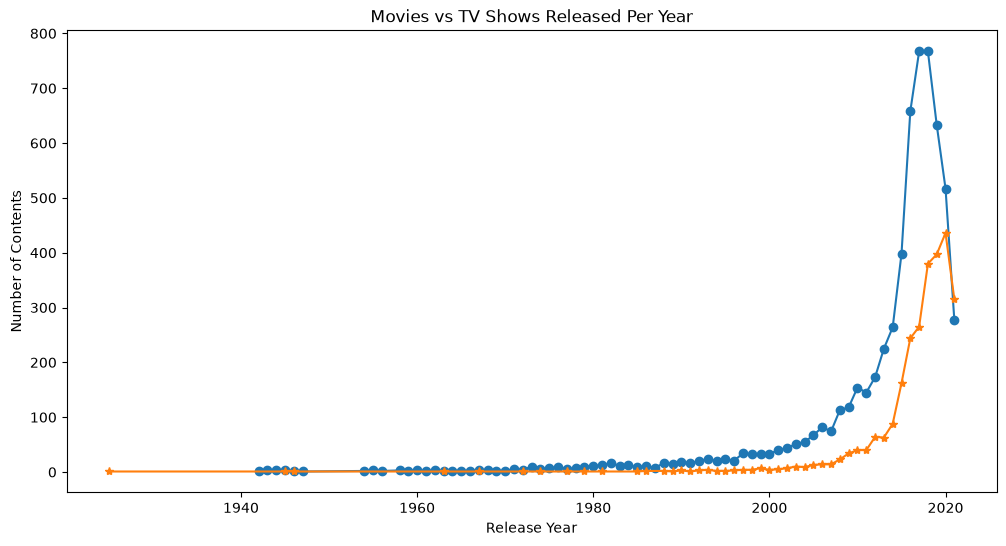

In [21]:
--9:
movies = a[a['type'] == 'Movie']
tv = a[a['type'] == 'TV Show']
movie_year = movies['release_year'].value_counts().sort_index()
tv_year = tv['release_year'].value_counts().sort_index()
plt.figure(figsize=(12, 6))

plt.plot(movie_year.index, movie_year.values, label='Movies', marker='o')
plt.plot(tv_year.index, tv_year.values, label='TV Shows', marker='*')
plt.xlabel('Release Year')
plt.ylabel('Number of Contents')
plt.title('Movies vs TV Shows Released Per Year')
plt.show()
     

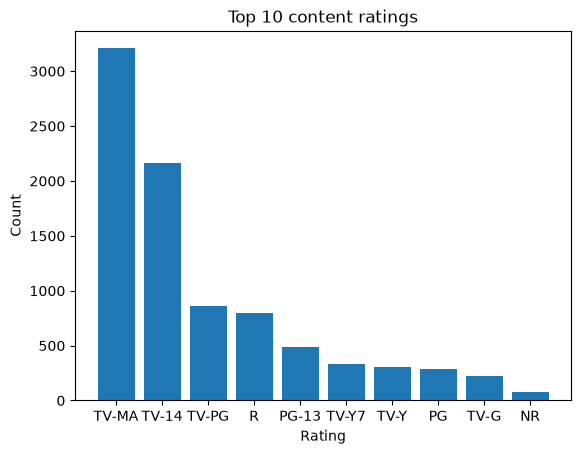

In [24]:
--7:
top_ratings = a['rating'].value_counts().head(10)
plt.bar(top_ratings.index, top_ratings.values)
plt.title('Top 10 content ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()